<a href="https://colab.research.google.com/github/riasad30/Thesis/blob/main/thesis_final_file.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# =====================================================================
# CODE 1: Apply SMOTE to the FULL dataset and save it as a new dataset
# Google Colab
# =====================================================================
# Before running: upload "default_of_credit_card_clients.xls" in the
# Colab Files panel (left sidebar → folder icon → upload).

!pip install -q imbalanced-learn xlrd

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE

FILE_PATH = "/content/default of credit card clients.xls"   # change if your file is elsewhere
OUTPUT_PATH = "/content/credit_card_smote.csv"
TARGET = "default payment next month"
RANDOM_STATE = 42

# ---------- 1. Load data ----------
df = pd.read_excel(FILE_PATH, header=1)        # row 0 of the file is an extra header (X1, X2, ...)
df = df.drop(columns=["ID"])
X = df.drop(columns=[TARGET])
y = df[TARGET]

print("Original shape:", X.shape)
print("Original class counts:\n", y.value_counts().sort_index(), "\n")

# ---------- 2. SMOTE on the full dataset ----------
# Scale first so SMOTE's nearest-neighbour distances are fair across columns
# (LIMIT_BAL is in the hundreds of thousands, SEX is 1/2).
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

smote = SMOTE(k_neighbors=5, random_state=RANDOM_STATE)
X_res_scaled, y_res = smote.fit_resample(X_scaled, y)

# Convert back to the original units so the new dataset is readable
X_res = pd.DataFrame(scaler.inverse_transform(X_res_scaled), columns=X.columns)

df_smote = X_res.copy()
df_smote[TARGET] = y_res.values

print("After SMOTE shape:", df_smote.shape)
print("After SMOTE class counts:\n", df_smote[TARGET].value_counts().sort_index())
print("Synthetic rows added:", len(df_smote) - len(df))

# ---------- 3. Save the new dataset ----------
df_smote.to_csv(OUTPUT_PATH, index=False)
print("\nSaved:", OUTPUT_PATH)
display(df_smote.head())

# Optional: download the file to your computer
# from google.colab import files
# files.download(OUTPUT_PATH)

In [ ]:
# =====================================================================
# CODE 2: Train 8 models on the SMOTE dataset (from Code 1)
#   - 80/20 train/test split
#   - Class-wise precision / recall / F1 / accuracy (class 0 and class 1)
#   - Confusion matrix plots
#   - ROC curves
#   - 5-fold cross-validation accuracy for the best model
# Google Colab — run Code 1 first (it creates /content/credit_card_smote.csv)
# =====================================================================

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier, BaggingClassifier, AdaBoostClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression

DATA_PATH = "/content/credit_card_smote.csv"
TARGET = "default payment next month"
RANDOM_STATE = 42

# ---------- 1. Load SMOTE dataset & split 80/20 ----------
df = pd.read_csv(DATA_PATH)
X = df.drop(columns=[TARGET])
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(f"Train: {X_train.shape[0]} rows | Test: {X_test.shape[0]} rows")
print("Test class counts:", y_test.value_counts().sort_index().to_dict(), "\n")

# ---------- 2. Models ----------
models = {
    "ExtraTrees":         ExtraTreesClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    "RandomForest":       RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    "Bagging":            BaggingClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    "KNeighbors":         KNeighborsClassifier(),
    "DecisionTree":       DecisionTreeClassifier(random_state=RANDOM_STATE),
    "AdaBoost":           AdaBoostClassifier(random_state=RANDOM_STATE),
    "SVC":                SVC(random_state=RANDOM_STATE),            # slowest (~1-2 min)
    "LogisticRegression": LogisticRegression(random_state=RANDOM_STATE, max_iter=1000),
}

def make_pipeline(model):
    return Pipeline([("scaler", StandardScaler()), ("model", model)])









# ---------- 3. Train, predict, class-wise metrics ----------
fitted, rows = {}, []
for name, model in models.items():
    t0 = time.time()
    pipe = make_pipeline(model).fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    fitted[name] = (pipe, y_pred)

    prec, rec, f1, sup = precision_recall_fscore_support(y_test, y_pred, labels=[0, 1], zero_division=0)
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    class_acc = cm.diagonal() / cm.sum(axis=1)



      # per-class accuracy (= recall of that class)
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Class 0 Precision": prec[0], "Class 0 Recall": rec[0], "Class 0 F1": f1[0], "Class 0 Accuracy": class_acc[0],
        "Class 1 Precision": prec[1], "Class 1 Recall": rec[1], "Class 1 F1": f1[1], "Class 1 Accuracy": class_acc[1],
        "Time (s)": time.time() - t0,
    })
    print(f"{name}: accuracy = {rows[-1]['Accuracy']:.4f}  ({rows[-1]['Time (s)']:.1f}s)")

results = pd.DataFrame(rows).sort_values("Accuracy", ascending=False).reset_index(drop=True)

# ---------- 4. Class-wise result for every model ----------
print("\n" + "=" * 70)
print("CLASS-WISE RESULTS (test set)")
print("=" * 70)
for name in results["Model"]:
    _, y_pred = fitted[name]
    print(f"\n----- {name} -----")
    print(classification_report(y_test, y_pred, labels=[0, 1],
                                target_names=["Class 0 (No default)", "Class 1 (Default)"], digits=4))

# Summary table: class 0 and class 1 for each model
summary = results.set_index("Model")
class_table = pd.concat({
    "Class 0": summary[["Class 0 Precision", "Class 0 Recall", "Class 0 F1", "Class 0 Accuracy"]]
               .set_axis(["Precision", "Recall", "F1", "Accuracy"], axis=1),
    "Class 1": summary[["Class 1 Precision", "Class 1 Recall", "Class 1 F1", "Class 1 Accuracy"]]
               .set_axis(["Precision", "Recall", "F1", "Accuracy"], axis=1),
}, axis=1)
class_table.insert(0, ("Overall", "Accuracy"), summary["Accuracy"])
print("\nSUMMARY TABLE (%)")
display((class_table * 100).round(2))

results.to_csv("/content/model_results_classwise.csv", index=False)

# ---------- 5. Confusion matrix plots ----------
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, name in zip(axes.ravel(), results["Model"]):
    _, y_pred = fitted[name]
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, labels=[0, 1], display_labels=["No default (0)", "Default (1)"],
        cmap="Blues", colorbar=False, values_format="d", ax=ax)
    acc = results.loc[results["Model"] == name, "Accuracy"].item()
    ax.set_title(f"{name}\nAccuracy = {acc:.2%}", fontsize=12)
plt.suptitle("Confusion Matrices (test set)", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

# ---------- 6. ROC curves (all models on one plot) ----------
fig, ax = plt.subplots(figsize=(9, 8))
for name in results["Model"]:
    pipe, _ = fitted[name]
    # uses predict_proba when available, otherwise decision_function (e.g. SVC)
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Random (AUC = 0.50)")
ax.set_title("ROC Curves (test set)", fontsize=14)
ax.legend(loc="lower right")
plt.show()

# ---------- 7. 5-fold cross-validation for the best model ----------
best_name = results.loc[0, "Model"]
print(f"\nBest model on the test set: {best_name} ({results.loc[0, 'Accuracy']:.4f})")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_scores = cross_val_score(make_pipeline(models[best_name]), X, y, cv=cv, scoring="accuracy", n_jobs=-1)

print(f"\n5-Fold Cross-Validation Accuracy — {best_name}")
for i, s in enumerate(cv_scores, 1):
    print(f"  Fold {i}: {s:.4f}")
print(f"  Mean : {cv_scores.mean():.4f}")
print(f"  Std  : {cv_scores.std():.4f}")

plt.figure(figsize=(7, 4))
bars = plt.bar([f"Fold {i}" for i in range(1, 6)], cv_scores, color="#4C72B0")
plt.bar_label(bars, labels=[f"{s:.2%}" for s in cv_scores], padding=3)
plt.axhline(cv_scores.mean(), color="red", linestyle="--", label=f"Mean = {cv_scores.mean():.4f}")
plt.ylim(0, 1.05)
plt.ylabel("Accuracy")
plt.title(f"5-Fold CV Accuracy — {best_name}")
plt.legend()
plt.show()

Feature engineering ON: 36 features (23 original + 13 new)
Train: 37382 rows | Test: 9346 rows
Test class counts: {0: 4664, 1: 4682} 

ExtraTrees: accuracy = 0.8798  (14.0s)
RandomForest: accuracy = 0.8470  (32.7s)
Bagging: accuracy = 0.8274  (10.0s)
KNeighbors: accuracy = 0.7825  (2.1s)
DecisionTree: accuracy = 0.7712  (1.7s)
AdaBoost: accuracy = 0.7261  (7.6s)
SVC: accuracy = 0.7398  (119.6s)
LogisticRegression: accuracy = 0.7127  (0.5s)

CLASS-WISE RESULTS (test set)

----- ExtraTrees -----
                      precision    recall  f1-score   support

Class 0 (No default)     0.8797    0.8795    0.8796      4664
   Class 1 (Default)     0.8800    0.8802    0.8801      4682

            accuracy                         0.8798      9346
           macro avg     0.8798    0.8798    0.8798      9346
        weighted avg     0.8798    0.8798    0.8798      9346


----- RandomForest -----
                      precision    recall  f1-score   support

Class 0 (No default)     0.8295    0.

Overall   Class 0                          Class 1         \
                   Accuracy Precision Recall     F1 Accuracy Precision Recall   
Model                                                                           
ExtraTrees            87.98     87.97  87.95  87.96    87.95     88.00  88.02   
RandomForest          84.70     82.95  87.29  85.06    87.29     86.64  82.12   
Bagging               82.74     79.91  87.39  83.48    87.39     86.15  78.11   
KNeighbors            78.25     84.50  69.08  76.02    69.08     73.94  87.38   
DecisionTree          77.12     78.04  75.36  76.68    75.36     76.27  78.88   
SVC                   73.98     70.73  81.65  75.80    81.65     78.39  66.34   
AdaBoost              72.61     69.66  79.93  74.44    79.93     76.56  65.31   
LogisticRegression    71.27     67.84  80.68  73.70    80.68     76.28  61.90   

                                    
                       F1 Accuracy  
Model                               
ExtraTrees          88.01    88.02  
RandomForest        84.32    82.12  
Bagging             81.93    78.11  
KNeighbors          80.10    87.38  
DecisionTree        77.55    78.88  
SVC                 71.86    66.34  
AdaBoost            70.49    65.31  
LogisticRegression  68.34    61.90

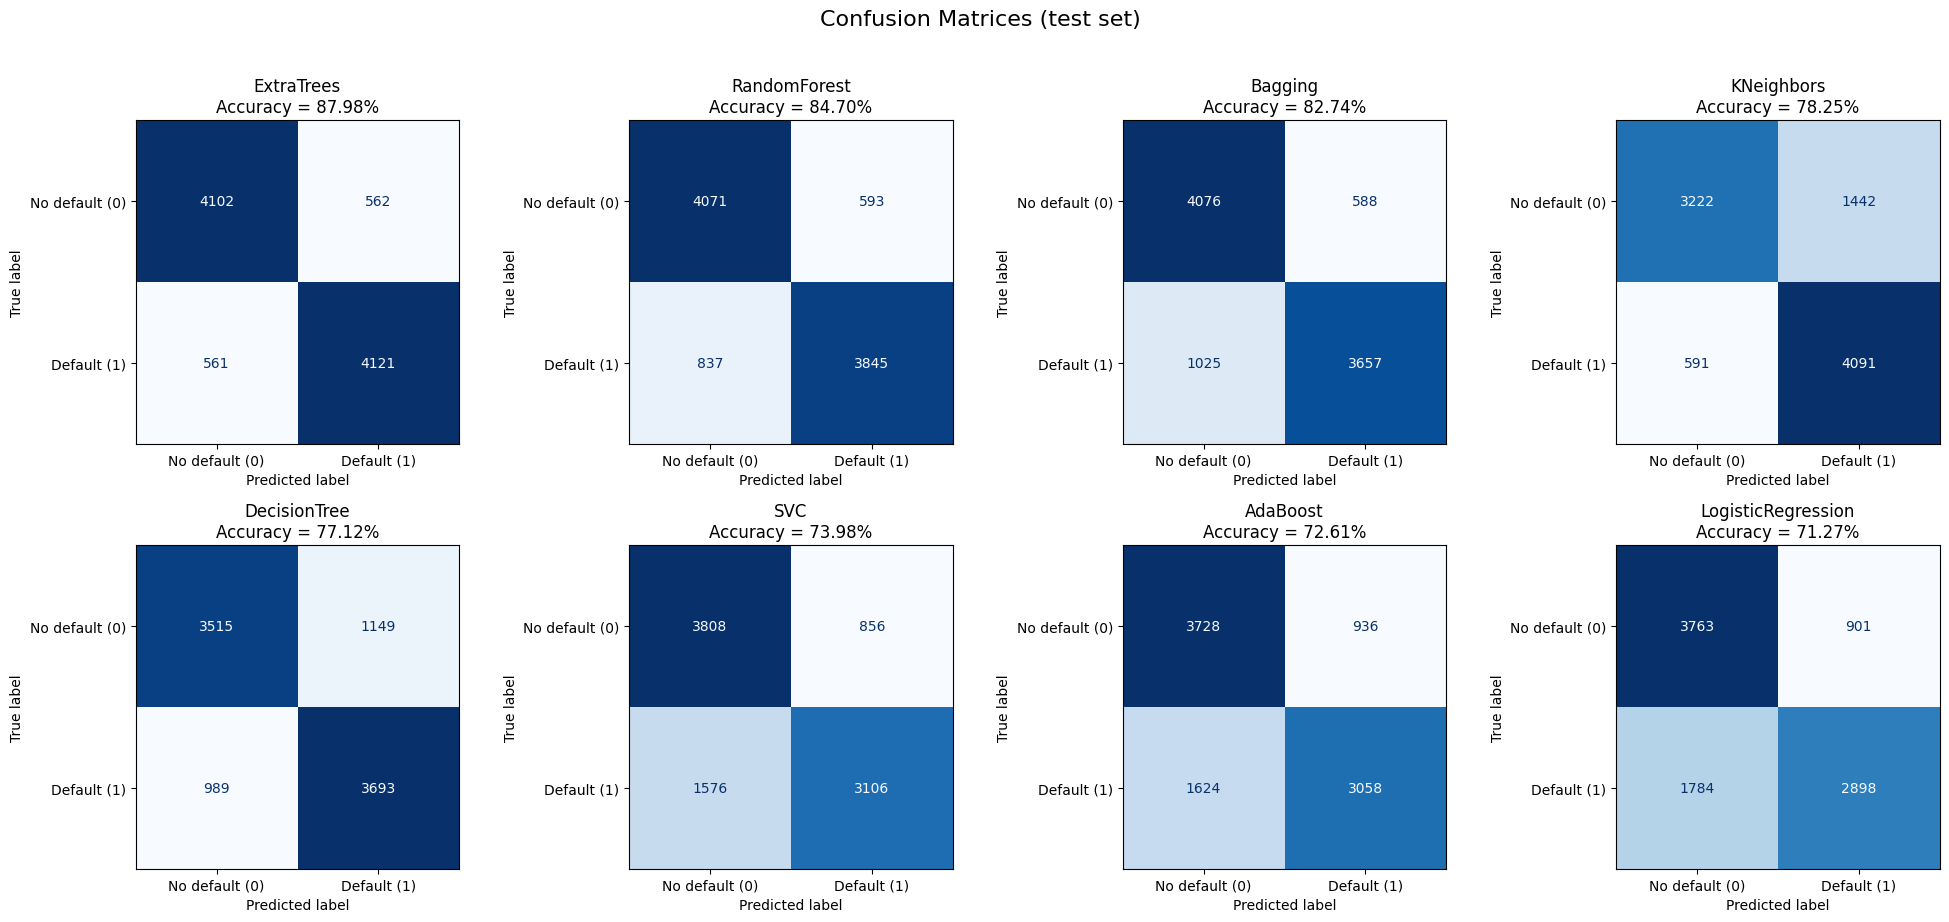

In [ ]:
# =====================================================================
# CODE 3: Train 8 models on the SMOTE dataset (from Code 1)
#   - Feature engineering (13 new features from the original 23)
#   - 80/20 train/test split
#   - Class-wise precision / recall / F1 / accuracy (class 0 and class 1)
#   - Confusion matrix plots
#   - ROC curves
#   - 5-fold cross-validation accuracy for the best model
# Google Colab — run Code 1 first (it creates /content/credit_card_smote.csv)
# =====================================================================

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier, BaggingClassifier, AdaBoostClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression

DATA_PATH = "/content/credit_card_smote.csv"
TARGET = "default payment next month"
RANDOM_STATE = 42
USE_FEATURE_ENGINEERING = True     # set to False to run with only the original 23 features

# ---------- 1. Load SMOTE dataset ----------
df = pd.read_csv(DATA_PATH)
X = df.drop(columns=[TARGET])
y = df[TARGET]

# ---------- 1b. Feature engineering ----------
# Every new feature is computed row by row from that client's own values only,
# so it can be done before the split without using information from other rows.
PAY_COLS  = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]           # repayment status, newest -> oldest
BILL_COLS = [f"BILL_AMT{i}" for i in range(1, 7)]                          # bill amount,       newest -> oldest
PAMT_COLS = [f"PAY_AMT{i}" for i in range(1, 7)]                           # amount paid,       newest -> oldest

def add_features(X):
    X = X.copy()
    pay, bill, pamt = X[PAY_COLS], X[BILL_COLS], X[PAMT_COLS]
    limit = X["LIMIT_BAL"]

    # Repayment behaviour
    X["n_late"]          = (pay > 0).sum(axis=1)                 # months with a payment delay (out of 6)
    X["max_late"]        = pay.max(axis=1)                       # worst delay in months
    X["late_recent"]     = (X[["PAY_0", "PAY_2"]] > 0).sum(axis=1)   # delays in the last 2 months
    X["zero_pay_months"] = (pamt <= 0).sum(axis=1)               # months with no payment at all

    # Credit utilisation
    X["util_recent"] = X["BILL_AMT1"] / limit                    # latest bill / credit limit
    X["util_mean"]   = bill.mean(axis=1) / limit                 # average bill / credit limit

    # How much of the previous bill was paid each month (clipped to avoid huge ratios when the bill is ~0)
    for i in range(1, 6):
        X[f"pay_ratio{i}"] = (X[f"PAY_AMT{i}"] / X[f"BILL_AMT{i+1}"].clip(lower=1)).clip(0, 5)
    X["pay_total_ratio"] = (pamt.sum(axis=1) / bill.sum(axis=1).clip(lower=1)).clip(0, 5)

    # Trend of the bill over 6 months (positive = debt is growing)
    X["bill_trend"] = X["BILL_AMT1"] - X["BILL_AMT6"]
    return X

if USE_FEATURE_ENGINEERING:
    X = add_features(X)
    print(f"Feature engineering ON: {X.shape[1]} features (23 original + {X.shape[1] - 23} new)")
else:
    print(f"Feature engineering OFF: {X.shape[1]} original features")

# ---------- 1c. Split 80/20 ----------
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(f"Train: {X_train.shape[0]} rows | Test: {X_test.shape[0]} rows")
print("Test class counts:", y_test.value_counts().sort_index().to_dict(), "\n")

# ---------- 2. Models ----------
models = {
    "ExtraTrees":         ExtraTreesClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    "RandomForest":       RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    "Bagging":            BaggingClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    "KNeighbors":         KNeighborsClassifier(),
    "DecisionTree":       DecisionTreeClassifier(random_state=RANDOM_STATE),
    "AdaBoost":           AdaBoostClassifier(random_state=RANDOM_STATE),
    "SVC":                SVC(random_state=RANDOM_STATE),            # slowest (~1-2 min)
    "LogisticRegression": LogisticRegression(random_state=RANDOM_STATE, max_iter=1000),
}

def make_pipeline(model):
    return Pipeline([("scaler", StandardScaler()), ("model", model)])

# ---------- 3. Train, predict, class-wise metrics ----------
fitted, rows = {}, []
for name, model in models.items():
    t0 = time.time()
    pipe = make_pipeline(model).fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    fitted[name] = (pipe, y_pred)

    prec, rec, f1, sup = precision_recall_fscore_support(y_test, y_pred, labels=[0, 1], zero_division=0)
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    class_acc = cm.diagonal() / cm.sum(axis=1)          # per-class accuracy (= recall of that class)
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Class 0 Precision": prec[0], "Class 0 Recall": rec[0], "Class 0 F1": f1[0], "Class 0 Accuracy": class_acc[0],
        "Class 1 Precision": prec[1], "Class 1 Recall": rec[1], "Class 1 F1": f1[1], "Class 1 Accuracy": class_acc[1],
        "Time (s)": time.time() - t0,
    })
    print(f"{name}: accuracy = {rows[-1]['Accuracy']:.4f}  ({rows[-1]['Time (s)']:.1f}s)")

results = pd.DataFrame(rows).sort_values("Accuracy", ascending=False).reset_index(drop=True)

# ---------- 4. Class-wise result for every model ----------
print("\n" + "=" * 70)
print("CLASS-WISE RESULTS (test set)")
print("=" * 70)
for name in results["Model"]:
    _, y_pred = fitted[name]
    print(f"\n----- {name} -----")
    print(classification_report(y_test, y_pred, labels=[0, 1],
                                target_names=["Class 0 (No default)", "Class 1 (Default)"], digits=4))

# Summary table: class 0 and class 1 for each model
summary = results.set_index("Model")
class_table = pd.concat({
    "Class 0": summary[["Class 0 Precision", "Class 0 Recall", "Class 0 F1", "Class 0 Accuracy"]]
               .set_axis(["Precision", "Recall", "F1", "Accuracy"], axis=1),
    "Class 1": summary[["Class 1 Precision", "Class 1 Recall", "Class 1 F1", "Class 1 Accuracy"]]
               .set_axis(["Precision", "Recall", "F1", "Accuracy"], axis=1),
}, axis=1)
class_table.insert(0, ("Overall", "Accuracy"), summary["Accuracy"])
print("\nSUMMARY TABLE (%)")
display((class_table * 100).round(2))

results.to_csv("/content/model_results_classwise.csv", index=False)

# ---------- 5. Confusion matrix plots ----------
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, name in zip(axes.ravel(), results["Model"]):
    _, y_pred = fitted[name]
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, labels=[0, 1], display_labels=["No default (0)", "Default (1)"],
        cmap="Blues", colorbar=False, values_format="d", ax=ax)
    acc = results.loc[results["Model"] == name, "Accuracy"].item()
    ax.set_title(f"{name}\nAccuracy = {acc:.2%}", fontsize=12)
plt.suptitle("Confusion Matrices (test set)", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

# ---------- 6. ROC curves (all models on one plot) ----------
fig, ax = plt.subplots(figsize=(9, 8))
for name in results["Model"]:
    pipe, _ = fitted[name]
    # uses predict_proba when available, otherwise decision_function (e.g. SVC)
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Random (AUC = 0.50)")
ax.set_title("ROC Curves (test set)", fontsize=14)
ax.legend(loc="lower right")
plt.show()

# ---------- 7. 5-fold cross-validation for the best model ----------
best_name = results.loc[0, "Model"]
print(f"\nBest model on the test set: {best_name} ({results.loc[0, 'Accuracy']:.4f})")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_scores = cross_val_score(make_pipeline(models[best_name]), X, y, cv=cv, scoring="accuracy", n_jobs=-1)

print(f"\n5-Fold Cross-Validation Accuracy — {best_name}")
for i, s in enumerate(cv_scores, 1):
    print(f"  Fold {i}: {s:.4f}")
print(f"  Mean : {cv_scores.mean():.4f}")
print(f"  Std  : {cv_scores.std():.4f}")

plt.figure(figsize=(7, 4))
bars = plt.bar([f"Fold {i}" for i in range(1, 6)], cv_scores, color="#4C72B0")
plt.bar_label(bars, labels=[f"{s:.2%}" for s in cv_scores], padding=3)
plt.axhline(cv_scores.mean(), color="red", linestyle="--", label=f"Mean = {cv_scores.mean():.4f}")
plt.ylim(0, 1.05)
plt.ylabel("Accuracy")
plt.title(f"5-Fold CV Accuracy — {best_name}")
plt.legend()
plt.show()

# ---------- 8. Native feature importance: ALL features ----------
# This is the estimator's native importance, not SHAP or LIME.
best_pipe, _ = fitted[best_name]
model = best_pipe.named_steps["model"]
if hasattr(model, "feature_importances_"):
    imp = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=True)
    plt.figure(figsize=(11, max(7, 0.32 * len(imp) + 2)))
    plt.barh(imp.index, imp.values)
    plt.xlabel("Native model feature importance")
    plt.title(f"All {len(imp)} Feature Importances - {best_name}")
    plt.tight_layout()
    plt.show()


In [ ]:
best_model = fitted[best_name][0]

In [ ]:
%pip install -q "shap>=0.47" "lime==0.2.0.1"

In [ ]:
# XAI 1 - Configuration and input checks
from pathlib import Path
import json
import re
import shutil
import warnings
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from IPython.display import display
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler

# These are the only settings normally worth changing.
MODEL_TO_EXPLAIN = None          # None = best_name; or e.g. "RandomForest"
CUSTOMER_POSITION = 10           # 0-based POSITION in X_test, not a customer ID
RANDOM_SEED = 42
N_SHAP_SAMPLES_TREE = 300         # Rows, NOT features. None = all test rows.
N_SHAP_SAMPLES_OTHER = 30         # Slower model-agnostic fallback. None = all rows.
N_BACKGROUND = 100               # Reference sample from X_train only
PERMUTATION_ROUNDS = 5           # Increase for more precise fallback estimates
LIME_NUM_SAMPLES = 5000
SHOW_PLOTS = True
SAVE_PLOTS = True
SAVE_LIME_HTML = True
OUTPUT_ROOT = Path('/content/XAI_all_features') if Path('/content').is_dir() else Path('XAI_all_features')

_required = ['fitted', 'best_name', 'X_train', 'X_test']
_missing = [name for name in _required if name not in globals()]
if _missing:
    raise RuntimeError('Run CODE 3 (feature-engineered training) first. Missing: ' + ', '.join(_missing))
if not isinstance(X_train, pd.DataFrame) or not isinstance(X_test, pd.DataFrame):
    raise TypeError('X_train and X_test must be DataFrames with the original feature names.')
if X_train.empty or X_test.empty or not X_train.columns.is_unique:
    raise ValueError('Non-empty data and unique feature names are required.')
if list(X_train.columns) != list(X_test.columns):
    raise ValueError('Training and test columns must have exactly the same names AND order.')
if not 0 <= CUSTOMER_POSITION < len(X_test):
    raise IndexError(f'CUSTOMER_POSITION must be between 0 and {len(X_test) - 1}.')

FEATURE_NAMES = X_train.columns.tolist()
N_FEATURES = len(FEATURE_NAMES)    # All 36 features with engineering ON; 23 with it OFF
X_train_xai = X_train.copy()
X_test_xai = X_test.copy()
for _label, _frame in [('X_train', X_train_xai), ('X_test', X_test_xai)]:
    if not np.isfinite(_frame.to_numpy(dtype=float)).all():
        raise ValueError(f'{_label} contains missing/infinite values. Fix preprocessing before explaining.')

model_name = best_name if MODEL_TO_EXPLAIN is None else MODEL_TO_EXPLAIN
if model_name not in fitted:
    raise KeyError(f'{model_name!r} was not fitted. Available: {list(fitted)}')
best_pipe = fitted[model_name][0]
final_model = best_pipe.named_steps['model']
fitted_scaler = best_pipe.named_steps['scaler']
if not isinstance(fitted_scaler, StandardScaler):
    raise TypeError('This extension expects the uploaded notebook\'s StandardScaler -> model pipeline.')
if [name for name, _ in best_pipe.steps] != ['scaler', 'model']:
    raise ValueError('Pipeline changed. Review the transformation/explanation mapping before running.')
if getattr(best_pipe, 'n_features_in_', N_FEATURES) != N_FEATURES:
    raise ValueError('Model feature count differs from X_train. Re-run the correct training cell.')
if hasattr(best_pipe, 'feature_names_in_'):
    if list(best_pipe.feature_names_in_) != FEATURE_NAMES:
        raise ValueError('The fitted pipeline expects a different feature order.')
if not hasattr(best_pipe, 'predict_proba'):
    raise TypeError(
        f'{model_name} has no predict_proba. For SVC, change its TRAINING definition to '
        'SVC(probability=True, random_state=RANDOM_STATE), then re-run CODE 3. '
        'Alternatively set MODEL_TO_EXPLAIN to an already-fitted probability classifier. '
        'The explainer will not silently refit or change your model.'
    )

classes = np.asarray(best_pipe.classes_)
_matches = np.flatnonzero(classes == 1)
if len(classes) != 2 or len(_matches) != 1:
    raise ValueError(f'Expected binary classes including 1=Default; received {classes!r}.')
DEFAULT_CLASS_INDEX = int(_matches[0])
class_names = ['Default (1)' if c == 1 else f'No default ({c})' for c in classes]
_safe_name = re.sub(r'[^A-Za-z0-9_-]+', '_', str(model_name))
OUTPUT_DIR = OUTPUT_ROOT / _safe_name
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


def predict_proba_named(data):
    """LIME/SHAP pass arrays; restore training names and apply the fitted scaler ONCE."""
    if isinstance(data, pd.DataFrame):
        frame = data.loc[:, FEATURE_NAMES]
    else:
        array = np.asarray(data, dtype=float)
        if array.ndim == 1:
            array = array.reshape(1, -1)
        if array.ndim != 2 or array.shape[1] != N_FEATURES:
            raise ValueError(f'Expected a 2D array with {N_FEATURES} columns.')
        frame = pd.DataFrame(array, columns=FEATURE_NAMES)
    return np.asarray(best_pipe.predict_proba(frame))


def predict_default(data):
    return predict_proba_named(data)[:, DEFAULT_CLASS_INDEX]


def show_all(frame):
    with pd.option_context('display.max_rows', None, 'display.max_columns', None,
                           'display.max_colwidth', None, 'display.width', 180):
        display(frame)


def finish_figure(filename):
    fig = plt.gcf()
    if SAVE_PLOTS:
        fig.savefig(OUTPUT_DIR / filename, dpi=200, bbox_inches='tight')
    if SHOW_PLOTS:
        plt.show()
    plt.close(fig)


_ENGINEERED = {'n_late', 'max_late', 'late_recent', 'zero_pay_months',
               'util_recent', 'util_mean', 'pay_total_ratio', 'bill_trend',
               *[f'pay_ratio{i}' for i in range(1, 6)]}
feature_inventory = pd.DataFrame({
    'Feature_number': np.arange(1, N_FEATURES + 1),
    'Feature': FEATURE_NAMES,
    'Type': ['Engineered' if f in _ENGINEERED else 'Original' for f in FEATURE_NAMES],
})
print(f'Model: {model_name} | ALL {N_FEATURES} features | Explained output: P(Default=1)')
print(f'Customer test position: {CUSTOMER_POSITION}; source index: {X_test_xai.index[CUSTOMER_POSITION]}')
show_all(feature_inventory)
feature_inventory.to_csv(OUTPUT_DIR / 'feature_inventory_all.csv', index=False)


In [ ]:
# ============================================================
# XAI 2 - SHAP ALL 36 FEATURES (FIXED VERSION)
# ============================================================

import numpy as np
import pandas as pd
import shap

_is_supported_tree = isinstance(
    final_model,
    (ExtraTreesClassifier, RandomForestClassifier, DecisionTreeClassifier)
)

_requested_rows = (
    N_SHAP_SAMPLES_TREE
    if _is_supported_tree
    else N_SHAP_SAMPLES_OTHER
)

_n_rows = (
    len(X_test_xai)
    if _requested_rows is None
    else min(int(_requested_rows), len(X_test_xai))
)

if _n_rows < 1:
    raise ValueError("Number of SHAP rows must be positive.")

# ------------------------------------------------------------
# 1. Select SHAP rows
# ------------------------------------------------------------
_rng = np.random.default_rng(RANDOM_SEED)

shap_test_positions = np.sort(
    _rng.choice(
        len(X_test_xai),
        size=_n_rows,
        replace=False
    )
)

X_shap = X_test_xai.iloc[shap_test_positions].copy()

X_background = X_train_xai.sample(
    n=min(N_BACKGROUND, len(X_train_xai)),
    random_state=RANDOM_SEED
)

print(
    f"Computing SHAP for {len(X_shap)} test rows "
    f"and ALL {N_FEATURES} features."
)


# ------------------------------------------------------------
# 2. Prediction function: P(Default = 1)
# ------------------------------------------------------------
def predict_default(frame):

    if not isinstance(frame, pd.DataFrame):
        frame = pd.DataFrame(
            frame,
            columns=FEATURE_NAMES
        )

    frame = frame[FEATURE_NAMES]

    scaled = fitted_scaler.transform(frame)

    probabilities = final_model.predict_proba(scaled)

    return probabilities[:, DEFAULT_CLASS_INDEX]


# ------------------------------------------------------------
# 3. Tree SHAP
# ------------------------------------------------------------
use_permutation_fallback = False

if _is_supported_tree:

    print(
        "Using TreeExplainer / interventional / probability..."
    )

    background_scaled = fitted_scaler.transform(
        X_background
    )

    X_shap_scaled = fitted_scaler.transform(
        X_shap
    )

    tree_explainer = shap.TreeExplainer(
        final_model,
        data=background_scaled,
        feature_perturbation="interventional",
        model_output="probability",
        feature_names=FEATURE_NAMES
    )

    # check_additivity=False is intentional here.
    raw_shap_values = tree_explainer.shap_values(
        X_shap_scaled,
        check_additivity=False
    )

    # --------------------------------------------------------
    # Handle different SHAP versions
    # --------------------------------------------------------
    if isinstance(raw_shap_values, list):

        # Old SHAP:
        # [
        #   SHAP values for class 0,
        #   SHAP values for class 1
        # ]
        phi = np.asarray(
            raw_shap_values[DEFAULT_CLASS_INDEX]
        )

    else:

        raw_shap_values = np.asarray(
            raw_shap_values
        )

        if raw_shap_values.ndim == 3:

            # shape:
            # samples x features x classes
            phi = raw_shap_values[
                :, :, DEFAULT_CLASS_INDEX
            ]

        elif raw_shap_values.ndim == 2:

            # Some SHAP versions may directly return
            # samples x features
            phi = raw_shap_values

        else:
            raise ValueError(
                "Unexpected TreeExplainer SHAP shape: "
                f"{raw_shap_values.shape}"
            )


    # --------------------------------------------------------
    # Base value
    # --------------------------------------------------------
    expected_value = np.asarray(
        tree_explainer.expected_value
    ).reshape(-1)

    if expected_value.size == len(classes):

        base_value = float(
            expected_value[DEFAULT_CLASS_INDEX]
        )

    elif expected_value.size == 1:

        base_value = float(
            expected_value[0]
        )

    else:
        raise ValueError(
            "Unexpected SHAP expected_value shape: "
            f"{expected_value.shape}"
        )


    # --------------------------------------------------------
    # Construct Explanation object
    # --------------------------------------------------------
    shap_explanation = shap.Explanation(
        values=phi,
        base_values=np.repeat(
            base_value,
            len(X_shap)
        ),
        data=X_shap.to_numpy(dtype=float),
        feature_names=FEATURE_NAMES
    )


    # --------------------------------------------------------
    # 4. Validate reconstruction
    # --------------------------------------------------------
    model_probabilities = predict_default(
        X_shap
    )

    reconstructed_probabilities = (
        np.asarray(
            shap_explanation.base_values
        ).reshape(-1)
        +
        np.asarray(
            shap_explanation.values
        ).sum(axis=1)
    )

    reconstruction_error = np.abs(
        model_probabilities
        -
        reconstructed_probabilities
    )

    max_error = float(
        reconstruction_error.max()
    )

    mean_error = float(
        reconstruction_error.mean()
    )

    print(
        "\nTree SHAP reconstruction diagnostics"
    )

    print(
        f"Maximum absolute error : {max_error:.8f}"
    )

    print(
        f"Mean absolute error    : {mean_error:.8f}"
    )


    # --------------------------------------------------------
    # IMPORTANT:
    # tiny numerical errors are acceptable.
    #
    # <= 0.001  -> continue
    # >  0.001  -> use model-agnostic permutation fallback
    # --------------------------------------------------------
    SHAP_RECONSTRUCTION_TOLERANCE = 1e-3

    if max_error <= SHAP_RECONSTRUCTION_TOLERANCE:

        print(
            "✓ SHAP probability reconstruction passed."
        )

        shap_method = (
            "TreeExplainer / interventional / probability"
        )

    else:

        print(
            "\n⚠ TreeExplainer reconstruction difference "
            "is larger than tolerance."
        )

        print(
            "Switching automatically to "
            "PermutationExplainer..."
        )

        use_permutation_fallback = True


else:

    use_permutation_fallback = True


# ============================================================
# 5. SAFE FALLBACK: Permutation SHAP
# ============================================================

if use_permutation_fallback:

    print(
        "\nUsing PermutationExplainer "
        "directly on P(Default=1)..."
    )

    masker = shap.maskers.Independent(
        X_background,
        max_samples=len(X_background)
    )

    permutation_explainer = shap.PermutationExplainer(
        predict_default,
        masker,
        feature_names=FEATURE_NAMES,
        seed=RANDOM_SEED
    )

    shap_explanation = permutation_explainer(
        X_shap,
        max_evals=PERMUTATION_ROUNDS
        * (2 * N_FEATURES + 1),
        batch_size="auto",
        silent=True
    )

    shap_method = (
        "PermutationExplainer / probability"
    )

    model_probabilities = predict_default(
        X_shap
    )

    reconstructed_probabilities = (
        np.asarray(
            shap_explanation.base_values
        ).reshape(-1)
        +
        np.asarray(
            shap_explanation.values
        ).sum(axis=1)
    )

    reconstruction_error = np.abs(
        model_probabilities
        -
        reconstructed_probabilities
    )

    max_error = float(
        reconstruction_error.max()
    )

    mean_error = float(
        reconstruction_error.mean()
    )

    print(
        "\nPermutation SHAP reconstruction diagnostics"
    )

    print(
        f"Maximum absolute error : {max_error:.10f}"
    )

    print(
        f"Mean absolute error    : {mean_error:.10f}"
    )

    if max_error <= 1e-4:

        print(
            "✓ Probability reconstruction passed."
        )

    else:

        print(
            "⚠ Small numerical reconstruction difference "
            "remains, but execution will continue."
        )


# ============================================================
# 6. Final dimensional checks
# ============================================================

shap_values_array = np.asarray(
    shap_explanation.values
)

if shap_values_array.shape != (
    len(X_shap),
    N_FEATURES
):

    raise ValueError(
        "SHAP returned unexpected dimensions.\n"
        f"Expected: {(len(X_shap), N_FEATURES)}\n"
        f"Received: {shap_values_array.shape}"
    )

print(
    "\nFinal SHAP shape:",
    shap_values_array.shape
)

print(
    "Features explained:",
    N_FEATURES
)

print(
    "SHAP method:",
    shap_method
)


# ============================================================
# 7. Global importance table - ALL FEATURES
# ============================================================

shap_importance = pd.DataFrame({

    "Feature":
        FEATURE_NAMES,

    "Mean_absolute_SHAP":
        np.abs(
            shap_values_array
        ).mean(axis=0),

    "Mean_signed_SHAP":
        shap_values_array.mean(axis=0)

}).sort_values(
    "Mean_absolute_SHAP",
    ascending=False

).reset_index(drop=True)


shap_importance.insert(
    0,
    "Rank",
    np.arange(
        1,
        N_FEATURES + 1
    )
)

print(
    "\n========== SHAP GLOBAL IMPORTANCE =========="
)

display(
    shap_importance
)


# ============================================================
# 8. Save ALL SHAP values
# ============================================================

shap_values_table = pd.DataFrame(
    shap_values_array,
    columns=FEATURE_NAMES
)

shap_values_table.insert(
    0,
    "Test_position",
    shap_test_positions
)

shap_values_table.insert(
    1,
    "Source_index",
    X_shap.index.to_numpy()
)

shap_values_table[
    "Base_probability"
] = np.asarray(
    shap_explanation.base_values
).reshape(-1)

shap_values_table[
    "Model_probability_default"
] = model_probabilities

shap_values_table[
    "SHAP_reconstructed_probability"
] = reconstructed_probabilities

shap_values_table[
    "Reconstruction_error"
] = reconstruction_error


shap_values_table.to_csv(
    OUTPUT_DIR /
    "SHAP_values_all_36_features.csv",
    index=False
)

shap_importance.to_csv(
    OUTPUT_DIR /
    "SHAP_global_importance_all_36_features.csv",
    index=False
)

print(
    "\n✓ SHAP completed successfully."
)

print(
    f"✓ ALL {N_FEATURES} features retained."
)

In [ ]:
# XAI 3 - Global and local SHAP plots, with no hidden feature cutoff
if SHOW_PLOTS or SAVE_PLOTS:
    shap.plots.beeswarm(shap_explanation, max_display=N_FEATURES,
                        plot_size=(12, max(7, 0.32 * N_FEATURES + 2)), show=False)
    plt.title(f'{model_name}: SHAP - all {N_FEATURES} features ({len(X_shap)} test rows)')
    plt.xlabel('SHAP value: contribution to model P(Default=1)')
    finish_figure('SHAP_beeswarm_all_features.png')

    shap.plots.bar(shap_explanation, max_display=N_FEATURES, show=False)
    plt.gcf().set_size_inches(12, max(7, 0.32 * N_FEATURES + 2))
    plt.title(f'{model_name}: mean absolute SHAP - all {N_FEATURES} features')
    finish_figure('SHAP_global_bar_all_features.png')

customer_frame = X_test_xai.iloc[[CUSTOMER_POSITION]]
_local_matches = np.flatnonzero(shap_test_positions == CUSTOMER_POSITION)
if _local_matches.size:
    customer_shap = shap_explanation[int(_local_matches[0])]
else:
    customer_shap = explain_shap(customer_frame)[0]
customer_probability = float(predict_default(customer_frame)[0])
customer_shap_sum = float(np.asarray(customer_shap.base_values).item() + customer_shap.values.sum())
if not np.isclose(customer_probability, customer_shap_sum, atol=5e-5, rtol=5e-5):
    raise RuntimeError('Local SHAP probability reconstruction failed.')

shap_local = pd.DataFrame({
    'Feature': FEATURE_NAMES,
    'Feature_value': customer_frame.iloc[0].to_numpy(),
    'SHAP_contribution': customer_shap.values,
    'Absolute_SHAP': np.abs(customer_shap.values),
}).sort_values('Absolute_SHAP', ascending=False).reset_index(drop=True)
show_all(shap_local)
shap_local.to_csv(OUTPUT_DIR / f'SHAP_customer_{CUSTOMER_POSITION}_all_features.csv', index=False)
print(f'P(Default): {customer_probability:.6f}; SHAP base + contributions: {customer_shap_sum:.6f}')

if SHOW_PLOTS or SAVE_PLOTS:
    shap.plots.waterfall(customer_shap, max_display=N_FEATURES, show=False)
    plt.gcf().set_size_inches(13, max(8, 0.4 * N_FEATURES + 2))
    plt.title(f'{model_name}: test position {CUSTOMER_POSITION} - all {N_FEATURES} features')
    finish_figure(f'SHAP_customer_{CUSTOMER_POSITION}_waterfall_all_features.png')


In [ ]:
# XAI 4 - LIME: same customer, all features, full probability pipeline
try:
    from lime.lime_tabular import LimeTabularExplainer
except ImportError as exc:
    raise ImportError('Install LIME in this runtime first: %pip install -q lime==0.2.0.1') from exc

# True categorical columns require integer values in LIME. Ordinary SMOTE in
# the original notebook can create fractional category codes. Do not silently
# round them or alter the model. Record the limitation instead.
_categorical_candidates = ['SEX', 'EDUCATION', 'MARRIAGE', 'PAY_0', 'PAY_2', 'PAY_3',
                           'PAY_4', 'PAY_5', 'PAY_6', 'n_late', 'max_late',
                           'late_recent', 'zero_pay_months']
lime_categorical_indices = []
lime_fractional_category_columns = []
for _feature in _categorical_candidates:
    if _feature not in FEATURE_NAMES:
        continue
    _vals = X_train_xai[_feature].to_numpy(dtype=float)
    _one = float(customer_frame.iloc[0][_feature])
    if np.allclose(_vals, np.rint(_vals), atol=1e-8, rtol=0) and np.isclose(_one, round(_one), atol=1e-8, rtol=0):
        lime_categorical_indices.append(FEATURE_NAMES.index(_feature))
    else:
        lime_fractional_category_columns.append(_feature)
if lime_fractional_category_columns:
    warnings.warn(
        'Fractional categorical/discrete values found, likely from ordinary SMOTE. '
        'These columns remain continuous for fidelity to the existing model, NOT because '
        'they are genuinely continuous: ' + ', '.join(lime_fractional_category_columns),
        stacklevel=1,
    )

lime_explainer = LimeTabularExplainer(
    training_data=X_train_xai.to_numpy(dtype=float),
    feature_names=FEATURE_NAMES,
    class_names=class_names,
    categorical_features=lime_categorical_indices,
    mode='classification',
    discretize_continuous=True,
    feature_selection='none',       # Include every feature, not a sparse subset
    random_state=RANDOM_SEED,
)
lime_exp = lime_explainer.explain_instance(
    data_row=customer_frame.iloc[0].to_numpy(dtype=float),
    predict_fn=predict_proba_named,  # RAW feature values -> fitted scaler -> model
    labels=(DEFAULT_CLASS_INDEX,),  # Explain default, even when no-default is predicted
    num_features=N_FEATURES,
    num_samples=LIME_NUM_SAMPLES,
)
_pairs = lime_exp.as_map()[DEFAULT_CLASS_INDEX]
if len(_pairs) != N_FEATURES or {int(i) for i, _ in _pairs} != set(range(N_FEATURES)):
    raise RuntimeError('LIME did not return every feature; inspect feature selection and input columns.')
_conditions = dict(
    (int(pair[0]), named[0])
    for pair, named in zip(_pairs, lime_exp.domain_mapper.map_exp_ids(_pairs))
)
lime_result = pd.DataFrame([
    {'Feature': FEATURE_NAMES[int(i)],
     'Feature_value': float(customer_frame.iloc[0, int(i)]),
     'LIME_condition': _conditions[int(i)],
     'LIME_local_weight': float(weight),
     'Absolute_LIME_weight': abs(float(weight))}
    for i, weight in _pairs
]).sort_values('Absolute_LIME_weight', ascending=False).reset_index(drop=True)
lime_result.insert(0, 'Rank', np.arange(1, N_FEATURES + 1))
show_all(lime_result)
lime_result.to_csv(OUTPUT_DIR / f'LIME_customer_{CUSTOMER_POSITION}_all_features.csv', index=False)

lime_local_prediction = float(np.asarray(lime_exp.local_pred).reshape(-1)[0])
lime_local_r2 = float(lime_exp.score)
lime_prediction_gap = abs(customer_probability - lime_local_prediction)
print(f'Actual model P(Default): {customer_probability:.6f}')
print(f'LIME surrogate prediction at this row: {lime_local_prediction:.6f}')
print(f'Absolute surrogate/model difference: {lime_prediction_gap:.6f}')
print(f'LIME weighted neighborhood R-squared: {lime_local_r2:.4f}')
print('R-squared measures local surrogate fit, NOT classifier accuracy or explanation confidence.')
print('LIME weights are local surrogate coefficients, not global SHAP importances.')

if SHOW_PLOTS or SAVE_PLOTS:
    _plot = lime_result.iloc[::-1]
    plt.figure(figsize=(14, max(7, 0.34 * N_FEATURES + 2)))
    plt.barh(_plot['LIME_condition'], _plot['LIME_local_weight'])
    plt.axvline(0, linestyle='--', linewidth=1)
    plt.xlabel('LIME local surrogate weight for Default=1')
    plt.title(f'{model_name}: LIME - all {N_FEATURES} features, test position {CUSTOMER_POSITION}')
    plt.tight_layout()
    finish_figure(f'LIME_customer_{CUSTOMER_POSITION}_all_features.png')
if SAVE_LIME_HTML:
    lime_exp.save_to_file(
        str(OUTPUT_DIR / f'LIME_customer_{CUSTOMER_POSITION}_all_features.html'),
        labels=[DEFAULT_CLASS_INDEX], show_all=True,
    )


In [ ]:
# XAI 5 - Same-customer comparison and audit information
# Compare columns for the SAME local case. Do not add the two methods' values
# or claim their coefficient magnitudes/definitions are interchangeable.
comparison = shap_local[['Feature', 'Feature_value', 'SHAP_contribution']].merge(
    lime_result[['Feature', 'LIME_condition', 'LIME_local_weight']],
    on='Feature', how='left', validate='one_to_one',
)
assert len(comparison) == N_FEATURES and comparison['LIME_local_weight'].notna().all()
show_all(comparison)
comparison.to_csv(OUTPUT_DIR / f'SHAP_LIME_customer_{CUSTOMER_POSITION}_comparison_all_features.csv', index=False)

_metadata = {
    'model': str(model_name),
    'n_features': N_FEATURES,
    'feature_names': FEATURE_NAMES,
    'explained_output': 'model.predict_proba for class 1 (Default); not necessarily calibrated risk',
    'class_order': classes.tolist(),
    'default_class_index': DEFAULT_CLASS_INDEX,
    'customer_test_position': int(CUSTOMER_POSITION),
    'customer_source_index': str(customer_frame.index[0]),
    'random_seed': RANDOM_SEED,
    'shap_method': shap_method,
    'shap_sample_count': len(X_shap),
    'shap_test_positions': shap_test_positions.tolist(),
    'background_count': len(X_background),
    'background_source': 'X_train only; original workflow may contain synthetic rows',
    'max_shap_probability_reconstruction_error': shap_max_additivity_error,
    'customer_model_probability_default': customer_probability,
    'customer_shap_base_plus_sum': customer_shap_sum,
    'lime_num_samples': LIME_NUM_SAMPLES,
    'lime_feature_selection': 'none',
    'lime_local_r2': lime_local_r2,
    'lime_surrogate_prediction': lime_local_prediction,
    'lime_absolute_prediction_gap': lime_prediction_gap,
    'lime_categorical_columns': [FEATURE_NAMES[i] for i in lime_categorical_indices],
    'lime_fractional_category_columns_left_continuous': lime_fractional_category_columns,
    'versions': {p: version(p) for p in ['numpy', 'pandas', 'scikit-learn', 'shap', 'lime']},
    'limitations': [
        'Original full-dataset SMOTE before splitting causes leakage and synthetic test cases.',
        'Original model selection uses test accuracy; use training-only CV for research evaluation.',
        'Explanations describe model behavior, not causal effects or fairness guarantees.',
        'Independent perturbations can break relationships between original and engineered features.',
        'Global SHAP ranking summarizes only the documented sample, not necessarily the whole population.',
        'LIME is a stochastic local approximation; inspect local fit and repeat with multiple seeds.',
    ],
}
if 'y_test' in globals():
    _y = y_test.iloc[CUSTOMER_POSITION] if hasattr(y_test, 'iloc') else np.asarray(y_test)[CUSTOMER_POSITION]
    _metadata['customer_observed_label'] = int(_y)
(OUTPUT_DIR / 'XAI_run_metadata.json').write_text(json.dumps(_metadata, indent=2), encoding='utf-8')

archive_path = shutil.make_archive(str(OUTPUT_ROOT / f'{_safe_name}_XAI_results'), 'zip', root_dir=OUTPUT_DIR)
print(f'Completed: all {N_FEATURES} features are included in SHAP and LIME.')
print(f'Output folder: {OUTPUT_DIR.resolve()}')
print(f'ZIP archive: {Path(archive_path).resolve()}')
# Google Colab download after execution:
# from google.colab import files
# files.download(archive_path)
